In [1]:
from deepface import DeepFace

print("DeepFace cargado correctamente")

modelo = DeepFace.build_model(
    model_name="Emotion",
    task="facial_attribute"
)

print("Modelo de expresiones cargado correctamente")


26-11-27 01:17:32 - Directory C:\Users\aleal\.deepface has been created
26-11-27 01:17:32 - Directory C:\Users\aleal\.deepface\weights has been created
DeepFace cargado correctamente
26-11-27 01:17:33 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to C:\Users\aleal\.deepface\weights\facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: C:\Users\aleal\.deepface\weights\facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 16.6MB/s]

Modelo de expresiones cargado correctamente


Expresion real: happy
Expresion predicha: happy


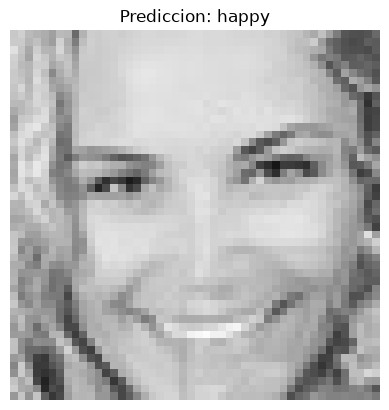

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

from time import time
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

folder_test = "FER2013/test"


folder = os.path.join(folder_test, "happy")

file_name = sorted(os.listdir(folder))[0]

imagen = cv2.imread(os.path.join(folder, file_name))

resultado = DeepFace.analyze(
    img_path=imagen,
    actions=["emotion"],
    detector_backend="skip",
    enforce_detection=False,
    silent=True
)

expresion = resultado[0]["dominant_emotion"]

print("Expresion real: happy")
print("Expresion predicha:", expresion)

plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
plt.title("Prediccion: " + expresion)
plt.axis("off")
plt.show()

In [4]:
folder = "FER2013/test"

class_names = sorted(
    c for c in os.listdir(folder)
    if os.path.isdir(os.path.join(folder, c))
)

y_real = []
y_pred = []

t0 = time()

for clase in class_names:

    print("Procesando:", clase)

    class_folder = os.path.join(folder, clase)

    for file_name in sorted(os.listdir(class_folder)):

        if file_name.lower().endswith((".jpg", ".png", ".jpeg")):

            imagen = cv2.imread(
                os.path.join(class_folder, file_name)
            )

            if imagen is None:
                continue

            obj = DeepFace.analyze(
                img_path=imagen,
                actions=["emotion"],
                detector_backend="skip",
                enforce_detection=False,
                silent=True
            )

            obj = obj[0]

            expresion = obj["dominant_emotion"]

            y_real.append(clase)
            y_pred.append(expresion)

    print("Imagenes procesadas:", len(y_pred))

tiempo_prediccion = time() - t0

print("\nResultados DeepFace")

print("Imagenes evaluadas:", len(y_real))

print("Accuracy:", accuracy_score(y_real, y_pred) * 100, "%")

print("Tiempo de prediccion:", tiempo_prediccion, "s")

print(classification_report(
    y_real,
    y_pred,
    labels=class_names,
    zero_division=0
))

Procesando: angry
Imagenes procesadas: 958
Procesando: disgust
Imagenes procesadas: 1069
Procesando: fear
Imagenes procesadas: 2093
Procesando: happy
Imagenes procesadas: 3867
Procesando: neutral
Imagenes procesadas: 5100
Procesando: sad
Imagenes procesadas: 6347
Procesando: surprise
Imagenes procesadas: 7178

Resultados DeepFace
Imagenes evaluadas: 7178
Accuracy: 56.366675954304824 %
Tiempo de prediccion: 88.40817785263062 s
              precision    recall  f1-score   support

       angry       0.50      0.43      0.46       958
     disgust       0.64      0.44      0.52       111
        fear       0.40      0.42      0.41      1024
       happy       0.77      0.77      0.77      1774
     neutral       0.46      0.56      0.51      1233
         sad       0.43      0.41      0.42      1247
    surprise       0.77      0.71      0.74       831

    accuracy                           0.56      7178
   macro avg       0.57      0.53      0.55      7178
weighted avg       0.57     

[[ 411   11  133   68  150  162   23]
 [  31   49   14    3    6    8    0]
 [  93    4  428   57  152  203   87]
 [  53    3   92 1363  153   77   33]
 [  80    3  127  121  689  195   18]
 [ 132    6  188  114  278  512   17]
 [  21    1   92   47   54   22  594]]


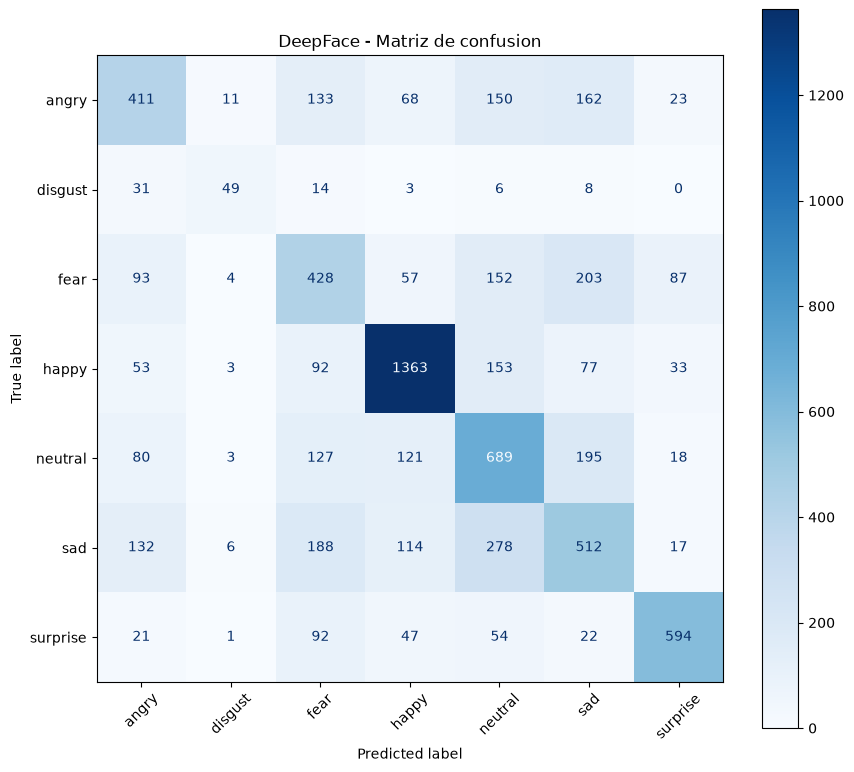

In [5]:
cm = confusion_matrix(
    y_real,
    y_pred,
    labels=class_names
)

print(cm)

fig, ax = plt.subplots(figsize=(9, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("DeepFace - Matriz de confusion")

plt.tight_layout()
plt.savefig("matriz_confusion_deepface.png", dpi=150)
plt.show()